# Crédito y alternativas de financiamiento

Primera descripción del panel, antes de estimar shocks de oferta. Se muestran dos poblaciones: el universo de personas agregado por acreedor y una cohorte de la muestra con saldo bancario en mayo de 2025.

**Lectura:** aumentar deuda fintech no demuestra reemplazo de crédito bancario. El saldo total y sus componentes se muestran juntos. Las cohortes no son grupos tratados y de control; difieren en selección y riesgo.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Permite ejecutar desde la raíz o desde cualquier subcarpeta del repositorio.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data/processed/ipc.dta').exists())
notebook_dir = root / 'Code/analysis/liquidez_fintech'
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from common import (ROOT, DATA, CENDEU, HERE, OUT, BASELINE, GROUPS, COLORS,
                    connect, lender_taxonomy, price_index, figure_style,
                    time_axis, save_figure, record_inputs)
figure_style()
pd.set_option('display.max_rows', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
con = connect()
tax = lender_taxonomy()
con.register('tax', tax)

## Ventana, precios y población

Pesos constantes de mayo de 2025, IPC nacional. Julio de 2026 no tiene IPC en el archivo actual y queda fuera de los gráficos reales. No se aproxima su precio con junio. La cohorte se fija antes del anuncio; no se selecciona por una caída posterior de crédito. Los gráficos pre-mayo están condicionados a pertenecer a esa cohorte futura, por lo que no son una prueba de tendencias paralelas.

In [2]:
ipc = price_index()
full_paths = sorted((CENDEU/'lender_month').glob('*.parquet'))
person_paths = sorted((CENDEU/'person_lender_5pct').glob('*.parquet'))
assert len(full_paths)==24 and len(person_paths)==24
record_inputs(full_paths + person_paths + [DATA/'ipc.dta', DATA/'balances_bancos.dta',
              ROOT/'Data/crosswalks/cendeu_lenders.csv'], '03')
monthly = con.execute("""
 SELECT p.year, p.month, coalesce(t.report_group,'Sin correspondencia') AS grupo,
        coalesce(t.include_credit,false) AS included,
        sum(p.credit_ars) AS amount_ars
 FROM read_parquet(?) p LEFT JOIN tax t USING(ent)
 WHERE borrower_type='person'
 GROUP BY 1,2,3,4
""",[str(CENDEU/'lender_month/*.parquet')]).fetchdf()
monthly['fecha'] = pd.to_datetime(dict(year=monthly.year,month=monthly.month,day=1))
monthly = monthly.merge(ipc[['fecha','deflactor']],on='fecha',how='left',validate='many_to_one')
monthly['real_amount'] = monthly.amount_ars*monthly.deflactor
excluded = monthly.groupby('fecha').apply(lambda d: 100*d.loc[~d.included,'amount_ars'].sum()/d.amount_ars.sum(), include_groups=False)
display(pd.DataFrame({'concepto':['Último mes nominal','Último mes con IPC','Mayor saldo excluido'],
 'valor':[f'{monthly.fecha.max():%m/%Y}',f'{monthly.loc[monthly.deflactor.notna(),"fecha"].max():%m/%Y}',f'{excluded.max():.3f}%']}))
monthly.to_csv(OUT/'universo_personas_mensual.csv',index=False)

,concepto,valor
0,Último mes nominal,07/2026
1,Último mes con IPC,06/2026
2,Mayor saldo excluido,0.069%


## Universo: magnitud y crecimiento de cada fuente

El panel izquierdo preserva las diferencias de escala. El derecho indexa cada fuente a su propio saldo de mayo: una suba porcentual grande sobre una base pequeña no equivale a compensación económica grande. Las exclusiones comprenden garantías y categorías desconocidas.

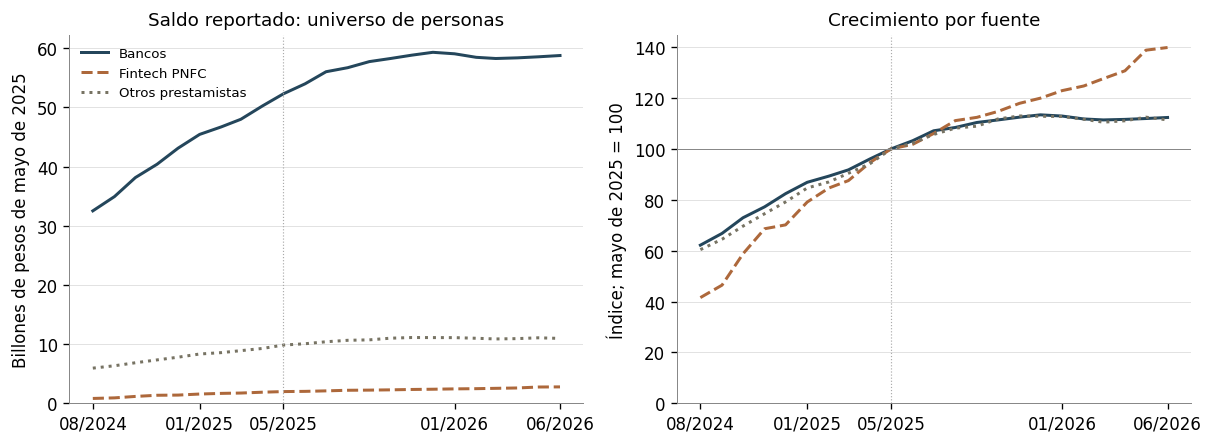

,saldo_base_billones,saldo_final_billones,variacion_real_pct
grupo,,,
Bancos,52.30,58.77,12.36
Fintech PNFC,1.99,2.78,39.86
Otros prestamistas,9.85,10.97,11.40


In [3]:
real = monthly.loc[monthly.included & monthly.deflactor.notna()].pivot(index='fecha',columns='grupo',values='real_amount').sort_index()
assert real.notna().all().all() and (real.loc[BASELINE]>0).all()
fig,axes = plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
styles = {'Bancos':'-','Fintech PNFC':'--','Otros prestamistas':':'}
for group in ['Bancos','Fintech PNFC','Otros prestamistas']:
    axes[0].plot(real.index,real[group]/1e12,label=group,color=COLORS[group],linestyle=styles[group])
    axes[1].plot(real.index,100*real[group]/real.loc[BASELINE,group],color=COLORS[group],linestyle=styles[group])
axes[0].set(title='Saldo reportado: universo de personas',ylabel='Billones de pesos de mayo de 2025',ylim=(0,None))
axes[1].set(title='Crecimiento por fuente',ylabel='Índice; mayo de 2025 = 100',ylim=(0,None))
axes[1].axhline(100,color='#888888',linewidth=.6)
for ax in axes:
    ax.axvline(BASELINE,color='#aaaaaa',linewidth=.7,linestyle=':')
    time_axis(ax,real.index)
axes[0].legend(fontsize=8)
save_figure(fig,'03_universo'); plt.show()
change = pd.DataFrame({'saldo_base_billones':real.loc[BASELINE]/1e12,
                      'saldo_final_billones':real.iloc[-1]/1e12,
                      'variacion_real_pct':100*(real.iloc[-1]/real.loc[BASELINE]-1)})
display(change)
change.to_csv(OUT/'universo_cambio_desde_mayo.csv')

## Cohortes fijas dentro de la muestra

Todas las personas tenían saldo bancario positivo en mayo. Se separan según tuvieran además PNFC fintech. No se excluyen quienes dejan de reportar saldo. Cada mes se cruza contra la lista inicial completa; una ausencia se contabiliza como **sin saldo observado**, no como cancelación verificada.

Los bancos incluyen los bancos digitales regulados; las financieras digitales se incluyen en otros prestamistas. La clasificación detallada está en `01` y `common.py`.

In [4]:
# Localizar mayo a partir del contenido, no de la posición implícita del archivo.
calendar = []
for path in person_paths:
    period = con.execute('SELECT DISTINCT year,month FROM read_parquet(?)',[str(path)]).fetchall()
    assert len(period)==1
    year,month=period[0]
    calendar.append((pd.Timestamp(year=year,month=month,day=1),path))
calendar=sorted(calendar)
assert len(set(date for date,_ in calendar))==24
baseline_path=dict(calendar)[BASELINE]
con.execute((HERE/'sql/cohort.sql').read_text(),[str(baseline_path)])
cohort_size = con.execute('SELECT cohort,count(*) AS personas,sum(baseline_amount) AS baseline_amount FROM cohort GROUP BY cohort').fetchdf()
display(cohort_size[['cohort','personas']])
assert cohort_size.personas.gt(0).all()
cohort_sql=(HERE/'sql/cohort_month.sql').read_text()
results=[]
for date,path in calendar:
    result=con.execute(cohort_sql,[str(path)]).fetchdf()
    result['fecha']=date
    results.append(result)
cohorts=pd.concat(results,ignore_index=True).merge(ipc[['fecha','deflactor']],on='fecha',how='left',validate='many_to_one')
for column in ['bank_amount','fintech_amount','other_amount','total_amount','npl_amount']:
    cohorts[column+'_real']=cohorts[column]*cohorts.deflactor
assert cohorts.groupby('cohort').cohort_n.nunique().eq(1).all()
assert np.allclose(cohorts.bank_amount+cohorts.fintech_amount+cohorts.other_amount,cohorts.total_amount)
base=cohorts.loc[cohorts.fecha.eq(BASELINE)].set_index('cohort')
check=base[['total_amount']].join(cohort_size.set_index('cohort')[['baseline_amount']])
assert np.allclose(check.total_amount,check.baseline_amount)
cohorts.to_csv(OUT/'cohortes_mensuales.csv',index=False)

,cohort,personas
0,Sin fintech PNFC previa,562719
1,Con fintech PNFC previa,148506


## ¿Qué fuente explica el cambio del saldo de la cohorte?

Cada curva es la variación del componente en pesos reales dividida por el **saldo total inicial de la misma cohorte**. Por construcción, los tres componentes suman la curva total. Se usa el mismo denominador incluso cuando no había fintech inicialmente; evita cocientes sobre cero y permite medir magnitud de compensación.

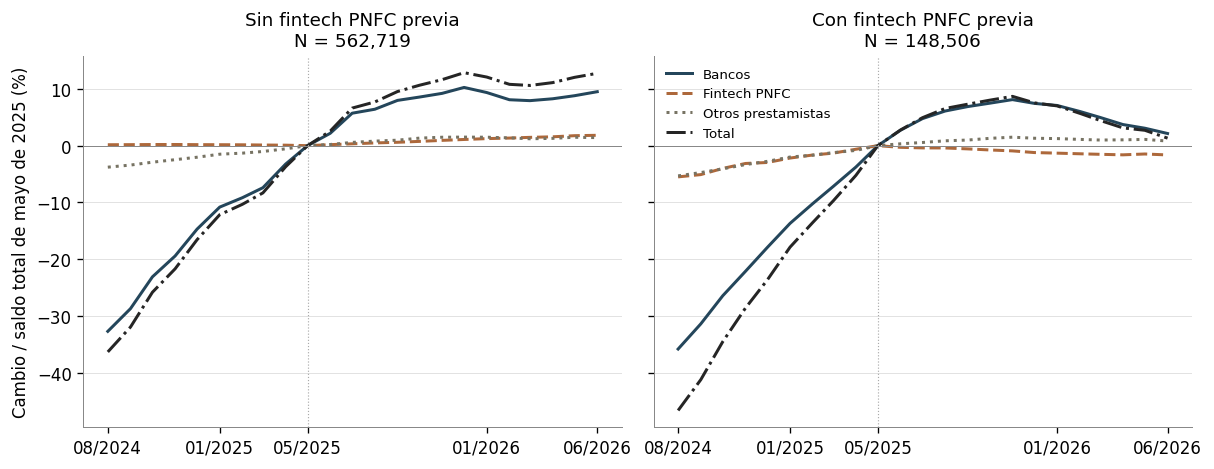

,Bancos,Fintech PNFC,Otros prestamistas,Total
cohort,,,,
Con fintech PNFC previa,2.14,-1.63,0.81,1.32
Sin fintech PNFC previa,9.50,1.82,1.41,12.73


In [5]:
plot_data=cohorts.loc[cohorts.deflactor.notna()].copy()
component_columns={'Bancos':'bank_amount_real','Fintech PNFC':'fintech_amount_real',
                   'Otros prestamistas':'other_amount_real','Total':'total_amount_real'}
fig,axes=plt.subplots(1,2,figsize=(10,3.8),sharey=True,layout='constrained')
cohort_order=['Sin fintech PNFC previa','Con fintech PNFC previa']
for ax,name in zip(axes,cohort_order):
    d=plot_data.loc[plot_data.cohort.eq(name)].sort_values('fecha')
    denominator=base.loc[name,'total_amount_real']
    for label,column in component_columns.items():
        contribution=100*(d[column]-base.loc[name,column])/denominator
        ax.plot(d.fecha,contribution,label=label,color=COLORS[label],
                linestyle={'Bancos':'-','Fintech PNFC':'--','Otros prestamistas':':','Total':'-.'}[label])
    ax.axhline(0,color='#888888',linewidth=.6)
    ax.axvline(BASELINE,color='#aaaaaa',linewidth=.7,linestyle=':')
    ax.set_title(f'{name}\nN = {int(d.cohort_n.iloc[0]):,}')
    time_axis(ax,d.fecha)
axes[0].set_ylabel('Cambio / saldo total de mayo de 2025 (%)')
axes[1].legend(fontsize=8)
save_figure(fig,'03_cohortes_componentes'); plt.show()
last=plot_data.fecha.max()
endpoint=plot_data.loc[plot_data.fecha.eq(last)].set_index('cohort')
contribution_table=pd.DataFrame({label:100*(endpoint[column]-base[column])/base.total_amount_real
                                for label,column in component_columns.items()})
assert np.allclose(contribution_table[['Bancos','Fintech PNFC','Otros prestamistas']].sum(axis=1),contribution_table.Total)
display(contribution_table.round(2))
contribution_table.to_csv(OUT/'cohortes_contribuciones_finales.csv')

## Continuidad de las relaciones reportadas

Porcentaje de la cohorte original con saldo bancario, fintech o algún saldo observado. El denominador es fijo. El resultado describe relaciones reportadas: una ausencia no demuestra exclusión ni cancelación, y una aparición no acredita originación.

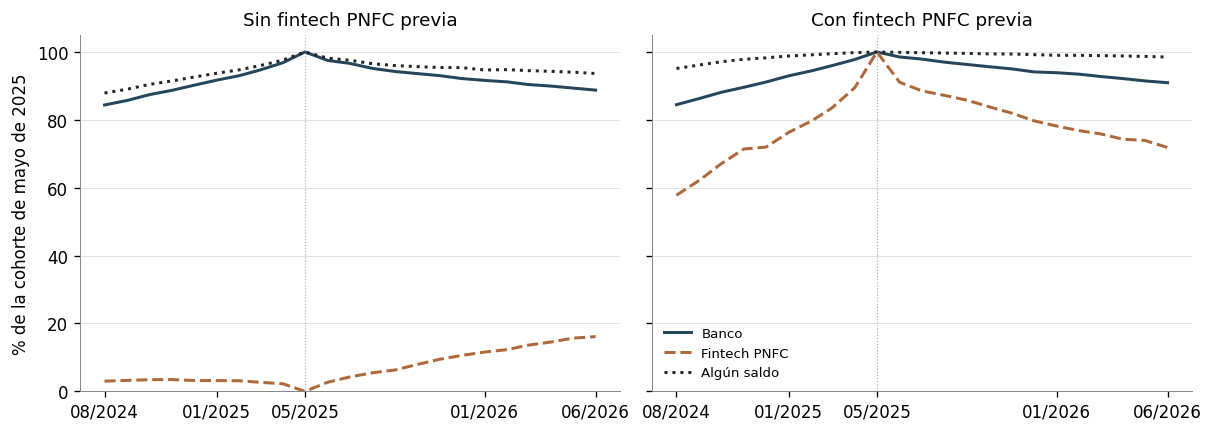

In [6]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),sharey=True,layout='constrained')
for ax,name in zip(axes,cohort_order):
    d=plot_data.loc[plot_data.cohort.eq(name)].sort_values('fecha')
    for column,label,style,color in [('with_bank','Banco','-',COLORS['Bancos']),
                                     ('with_fintech','Fintech PNFC','--',COLORS['Fintech PNFC']),
                                     ('with_credit','Algún saldo',':',COLORS['Total'])]:
        ax.plot(d.fecha,100*d[column]/d.cohort_n,label=label,linestyle=style,color=color)
    ax.axvline(BASELINE,color='#aaaaaa',linewidth=.7,linestyle=':')
    ax.set(title=name,ylim=(0,105)); time_axis(ax,d.fecha)
axes[0].set_ylabel('% de la cohorte de mayo de 2025')
axes[1].legend(fontsize=8)
save_figure(fig,'03_cohortes_continuidad'); plt.show()

## Concentración: cuánto depende la categoría de una entidad

Fintech PNFC es un grupo estrecho y concentrado. Su evolución puede reflejar principalmente una plataforma; los millones de relaciones no son millones de shocks independientes.

,name,amount_ars,share
159,MERCADOLIBRE S.R.L.,"1,422,821,530,000.00",0.72
31,CREDICUOTAS CONSUMO S.A.,"323,064,057,000.00",0.16
160,Crédito Directo S.A.,"88,504,407,000.00",0.04
75,CREDITECH SA,"67,289,822,000.00",0.03
117,Waynicoin S.A.,"39,524,451,000.00",0.02
76,Moni Online S.A.,"28,954,690,000.00",0.01
32,Delivery Hero Financial Services SA,"16,535,474,000.00",0.01


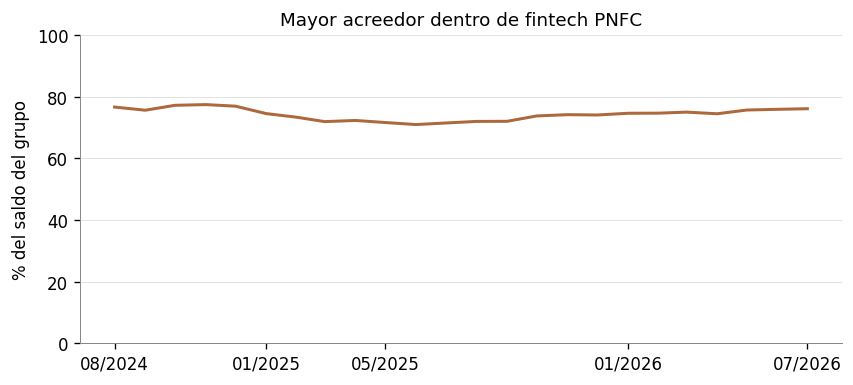

In [7]:
concentration=con.execute("""
 SELECT p.ent,t.name,p.year,p.month,sum(p.credit_ars) AS amount_ars
 FROM read_parquet(?) p JOIN tax t USING(ent)
 WHERE borrower_type='person' AND t.is_fintech
 GROUP BY 1,2,3,4
""",[str(CENDEU/'lender_month/*.parquet')]).fetchdf()
concentration['fecha']=pd.to_datetime(dict(year=concentration.year,month=concentration.month,day=1))
concentration['share']=concentration.amount_ars/concentration.groupby('fecha').amount_ars.transform('sum')
concentration.to_csv(OUT/'concentracion_fintech.csv',index=False)
display(concentration.loc[concentration.fecha.eq(BASELINE),['name','amount_ars','share']].sort_values('share',ascending=False))
top=concentration.groupby('fecha').share.max()
fig,ax=plt.subplots(figsize=(7,3.1),layout='constrained')
ax.plot(top.index,100*top,color=COLORS['Fintech PNFC'])
ax.set(title='Mayor acreedor dentro de fintech PNFC',ylabel='% del saldo del grupo',ylim=(0,100))
time_axis(ax,top.index); save_figure(fig,'03_concentracion'); plt.show()

## Cambios bancarios y fintech en la misma persona

Se clasifica a toda la cohorte, sin elegir solamente quienes pierden crédito. **Estable** significa un cambio real de hasta ±1% del saldo total inicial de la persona; el umbral es común a ambos componentes. Se compara mayo de 2025 con el último mes con IPC. Cada panel suma 100% de su cohorte.

La celda «cae banco / sube fintech» es un patrón compatible con reemplazo, no una estimación causal. Los ceros son ausencia de saldo reportado. Se muestra sensibilidad a umbrales de 0%, 1% y 5%.

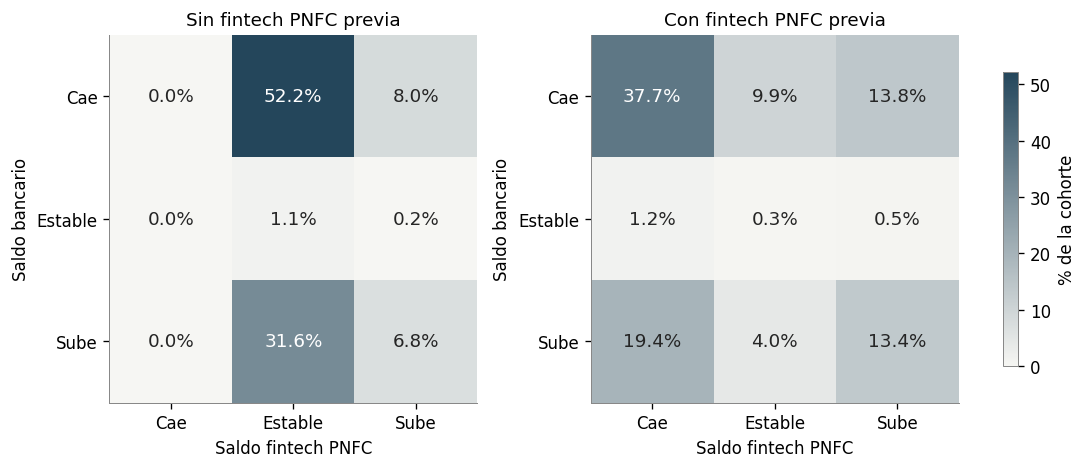

threshold,Umbral 0%,Umbral 1%,Umbral 5%
cohort,,,
Con fintech PNFC previa,17.44,13.82,8.07
Sin fintech PNFC previa,8.94,8.04,5.36


In [8]:

from matplotlib.colors import LinearSegmentedColormap
last_path=dict(calendar)[last]
deflator_end=ipc.loc[ipc.fecha.eq(last),'deflactor'].item()
query=(HERE/'sql/joint_changes.sql').read_text()
all_bins=[]
for threshold in [0.0,0.01,0.05]:
    result=con.execute(query,[str(baseline_path),str(last_path),deflator_end,deflator_end,
                              threshold,threshold,threshold,threshold]).fetchdf()
    result['threshold']=threshold
    result['pct']=100*result.personas/result.groupby('cohort').personas.transform('sum')
    counts=result.groupby('cohort').personas.sum().sort_index()
    assert counts.equals(cohort_size.set_index('cohort').personas.sort_index())
    all_bins.append(result)
joint=pd.concat(all_bins,ignore_index=True)
joint.to_csv(OUT/'cambios_individuales_conjuntos.csv',index=False)
selected=joint.loc[joint.threshold.eq(0.01)]
order=['Cae','Estable','Sube']
matrices=[selected.loc[selected.cohort.eq(name)].pivot(index='bank_bin',columns='fintech_bin',values='pct').reindex(index=order,columns=order).fillna(0) for name in cohort_order]
assert all(np.isclose(matrix.to_numpy().sum(),100) for matrix in matrices)
vmax=max(matrix.to_numpy().max() for matrix in matrices)
cmap=LinearSegmentedColormap.from_list('paper_blue',['#f6f6f3','#24465B'])
fig,axes=plt.subplots(1,2,figsize=(9,3.8),layout='constrained')
for ax,name,matrix in zip(axes,cohort_order,matrices):
    im=ax.imshow(matrix,vmin=0,vmax=vmax,cmap=cmap)
    ax.set_xticks(range(3),order); ax.set_yticks(range(3),order)
    ax.set(title=name,xlabel='Saldo fintech PNFC',ylabel='Saldo bancario')
    for row in range(3):
        for col in range(3):
            value=matrix.iloc[row,col]
            ax.text(col,row,f'{value:.1f}%',ha='center',va='center',
                    color='white' if value>vmax*.6 else '#252525',fontsize=11)
fig.colorbar(im,ax=axes,label='% de la cohorte',shrink=.8)
save_figure(fig,'03_cambios_conjuntos'); plt.show()
sensitivity=joint.loc[joint.bank_bin.eq('Cae') & joint.fintech_bin.eq('Sube')].pivot(index='cohort',columns='threshold',values='pct')
display(sensitivity.rename(columns={0.0:'Umbral 0%',0.01:'Umbral 1%',0.05:'Umbral 5%'}))


## Comprobaciones e interpretación

Las reconciliaciones anteriores verifican suma de componentes y tamaño fijo de cohorte. Se contrasta además la cohorte inicial con una agregación directa por persona y se informa la evolución observada. No se interpreta el cambio como un efecto causal de tasas o LEFI.

In [9]:
# Segunda forma de calcular el saldo inicial: SQL directo, sin los agregados por componente.
independent=con.execute("""
 SELECT c.cohort,sum(p.amount_ars) AS direct_total
 FROM read_parquet(?) p JOIN cohort c USING(cuit) JOIN tax t USING(ent)
 WHERE p.amount_ars>0 AND t.include_credit GROUP BY c.cohort
""",[str(baseline_path)]).fetchdf().set_index('cohort')
assert np.allclose(base.total_amount.sort_index(),independent.direct_total.sort_index())
for name in cohort_order:
    values=contribution_table.loc[name]
    no_balance=100*endpoint.loc[name,'no_reported_balance']/endpoint.loc[name,'cohort_n']
    display(Markdown(f'**{name}.** Entre mayo de 2025 y {last:%m/%Y}, el saldo total real reportado cambia **{values.Total:+.1f}%**. '
                     f'El componente bancario aporta **{values["Bancos"]:+.1f} puntos**, fintech **{values["Fintech PNFC"]:+.1f}** y otros prestamistas **{values["Otros prestamistas"]:+.1f}**. '
                     f'Al final, **{no_balance:.1f}%** no presenta saldo positivo entre los acreedores incluidos.'))
con.close()

**Sin fintech PNFC previa.** Entre mayo de 2025 y 06/2026, el saldo total real reportado cambia **+12.7%**. El componente bancario aporta **+9.5 puntos**, fintech **+1.8** y otros prestamistas **+1.4**. Al final, **6.3%** no presenta saldo positivo entre los acreedores incluidos.

**Con fintech PNFC previa.** Entre mayo de 2025 y 06/2026, el saldo total real reportado cambia **+1.3%**. El componente bancario aporta **+2.1 puntos**, fintech **-1.6** y otros prestamistas **+0.8**. Al final, **1.5%** no presenta saldo positivo entre los acreedores incluidos.

El próximo paso es distinguir cambios de demanda, reporte y oferta por relación. Estas curvas no seleccionan a clientes con contracción bancaria ni construyen un contrafactual. Antes de estimar shocks: revisar transferencias HSBC/Galicia, persistencia del reporte, moneda/producto no observados y concentración de fintech. Un aumento de fintech mientras también crecen los bancos puede ser expansión conjunta; no basta para afirmar sustitución.